In [8]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as snb
from tqdm import tqdm 
import os


# Data Import 

In [ ]:
DATA_LOADING_BENCHMARK_CSV = r"C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\data_loading_benchmark\_benchmark\data_loading\data_loading_benchmark.csv"
df = pd.read_csv(DATA_LOADING_BENCHMARK_CSV)


# DataLoader Benchmark Metrics

When benchmarking PyTorch `DataLoader` with multiple workers, we can evaluate **three key metrics**:

1. **Speedup (Sₙ)**  
   \[
   S_n = \frac{T_1}{T_n}
   \]  
   - How much faster the DataLoader runs with `n` workers compared to 1 worker.  
   - **Sₙ = 1** → no speedup; **Sₙ ≈ n** → perfect linear scaling.

2. **Efficiency (Eₙ)**  
   \[
   E_n = \frac{S_n}{n}
   \]  
   - Fraction of theoretical performance achieved per worker.  
   - **Eₙ = 1** → perfect use of resources; drops with overhead or contention.

3. **Compute Performance / Throughput (Pₙ)**  
   \[
   P_n = \frac{\text{work}}{T_n}
   \]  
   - Work done per unit of time (e.g., images/ms).  
   - Higher is better; shows absolute processing speed regardless of speedup.

**How to interpret together:**  
- **Speedup** tells if adding workers reduces runtime.  
- **Efficiency** shows if extra workers are effectively used.  
- **Compute Performance** shows how fast the data is actually processed.  

> ✅ Sweet spot: Number of workers that maximizes throughput while keeping efficiency reasonable.


# calculate speedup and compute performance

                     T_n        S_n       E_n        P_n
num_workers                                             
1            9603.219892   1.000000  1.000000   6.247904
2            4800.919661   2.000288  1.000144  12.497606
4            2665.824519   3.602345  0.900586  22.507108
8            1350.798370   7.109292  0.888661  44.418176
12            962.420466   9.978196  0.831516  62.342814
24            713.112455  13.466628  0.561109  84.138202


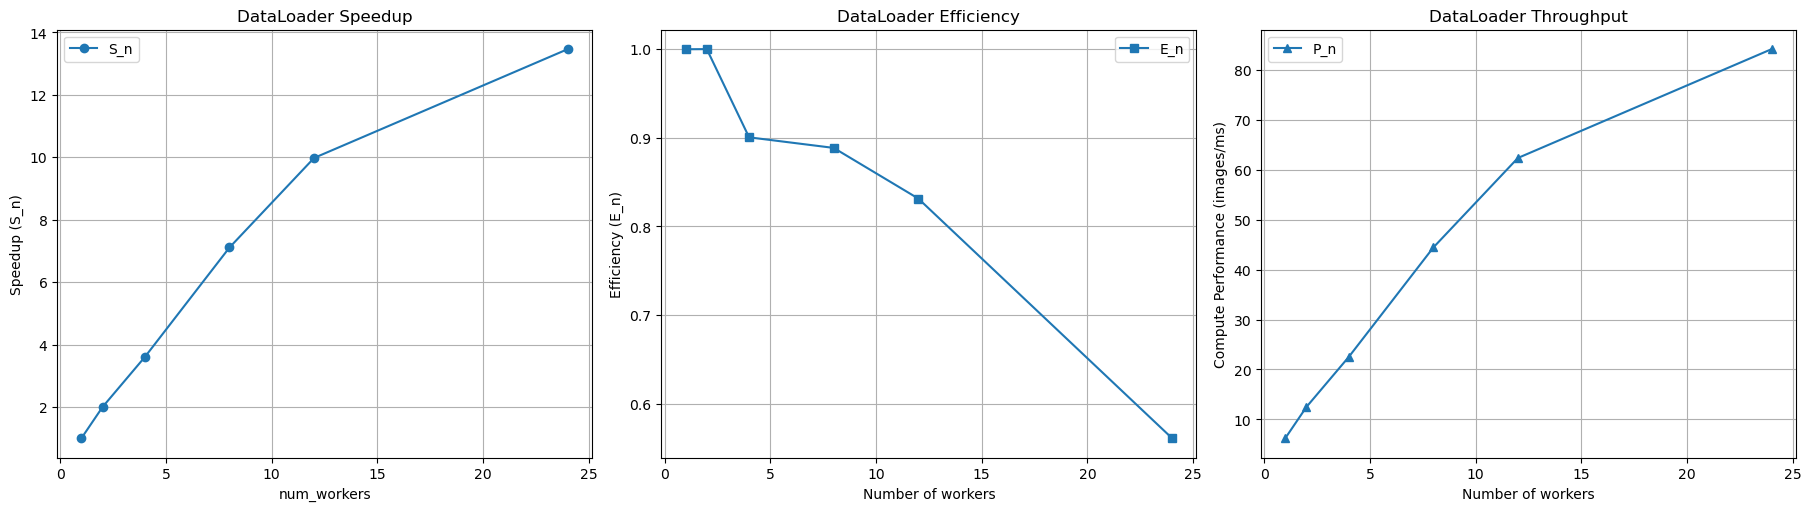

In [31]:
# Define total work (number of images processed)
work = 60000  # full FashionMNIST dataset

# Aggregate runtimes per number of workers
df_stats = df.groupby("num_workers")["runtime_ms"].mean().to_frame("T_n")

# Calculate Speedup S_n = T1 / Tn
T1 = df_stats.loc[1, "T_n"]
df_stats["S_n"] = T1 / df_stats["T_n"]

# Calculate Efficiency E_n = S_n / n
df_stats["E_n"] = df_stats["S_n"] / df_stats.index

# Compute Performance P_n = work / Tn (images per millisecond)
df_stats["P_n"] = work / df_stats["T_n"]

print(df_stats)
# Plot metrics
fig, axes = plt.subplots(1, 3, figsize=(18,5), layout="constrained")

# Speedup
df_stats["S_n"].plot(marker="o", ax=axes[0], grid=True)
x = df_stats.index.values  # number of workers
axes[0].set_ylabel("Speedup (S_n)")
axes[0].set_title("DataLoader Speedup")
axes[0].legend()

# Efficiency
df_stats["E_n"].plot(marker="s", ax=axes[1], grid=True)
axes[1].set_xlabel("Number of workers")
axes[1].set_ylabel("Efficiency (E_n)")
axes[1].set_title("DataLoader Efficiency")
axes[1].legend()

# Compute Performance
df_stats["P_n"].plot(marker="^", ax=axes[2], grid=True)
axes[2].set_xlabel("Number of workers")
axes[2].set_ylabel("Compute Performance (images/ms)")
axes[2].set_title("DataLoader Throughput")
axes[2].legend()

plt.show()
